# Prosody & grammatical categories

**Question.** How much grammatical information is carried by prosody, and
which grammatical distinctions is prosody actually sensitive to?

**Pipeline.**

| § | Stage | What happens |
|---|-------|--------------|
| 1 | Setup | imports, paths, feature preprocessing |
| 2 | Extract | one binary prosodic vector per occurrence; no unit or category decision yet |
| 3 | Discover | one test, two levels — which category splits and which form distinctions are prosodically real |
| 4 | Select | apply the criteria, choose the scheme (units + categories) |
| 5 | Pool & describe | build unit vectors, stability matrix, overlaps, bridge words, radar charts |

**Feature set.** `FEATURE_SET` in §1 switches between all prosodic features and
acoustic-only (syllable duration, pitch height, range, slope, semitones —
computed automatically from the signal). The prosodic-structure features
(feet, groups, packages) derive from native listeners' prominence judgments,
so they may encode the annotators' syntactic knowledge; the acoustic-only run
is the control for that. Run the notebook twice and compare.

**Effect size.** Every test reports `eta2` — the share of prosodic variance the
split explains (see §3). It is comparable across categories of different sizes;
the raw `ratio` is not (ratio ≈ eta2 × n).


## §1 Setup & feature preprocessing

In [1]:
import sys
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

from scipy.stats import entropy
from sklearn.metrics.pairwise import cosine_similarity


TOD_PATH      = "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/tod"
GREX_PATH     = "/Users/madalina/Documents/M2TAL/stage/grex/grex2"
TREEBANK_PATH = "/Users/madalina/Documents/PHD/code/data/SUD_French-Rhapsodie/prosody_no_punct.conllu"
# TREEBANK_PATH = "/Users/madalina/Documents/PHD/code/data/pSUD_Naija-NSC"
PATTERNS_FILE = "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/scripts/3. probability_matrix/patterns_all_nodes_prosody.txt"

GREW_PATTERN      = "pattern{X[upos<>PUNCT]}"


for p in (TOD_PATH, GREX_PATH):
    if p not in sys.path:
        sys.path.insert(1, p)

import pyximport
pyximport.install()

import grewpy
from grewpy import Corpus, CorpusDraft, Request

import tod.corpus  # noqa: F401  (registers handlers; keep import)

import grex.data           # noqa: F401
import grex.utils
import grex.features       # noqa: F401
import grex.data_prosody

grewpy.set_config("sud")

# ── Which features to use ────────────────────────────────────────────────
#   "all"      : every prosodic feature (structure + acoustics + contours)
#   "acoustic" : only signal-derived syllable acoustics, i.e. nothing that
#                depends on a human prominence judgment
FEATURE_SET = "all"

ACOUSTIC_MEASURES = ("Duration", "AvgHeightGlo", "PitchRangeGlo", "SlopeGlo",
                     "SemitonesFromUtteranceMean")


connected to port: 50392


In [2]:
# ── Drop entirely: redundant, unreliable, or too fine-grained ─────────────
FEATURES_TO_DROP = {
    'MeanF0',           # use SemitonesFromUtteranceMean instead (speaker-normalised)
    'MeanF0Step',       # threshold artefact, not a prosodic observation
    'AvgAmplitude',     # recording-condition-dependent
    'MaxAmplitude',     # same
    'SylForm',          # phonetic transcription, too fine-grained
    'AlignBegin',       # timing offset, not linguistic
    'AlignEnd',         # timing offset, not linguistic
    'pauseID',          # identifier, not a feature
    # Before*/Next* equivalents of dropped features:
    'BeforeMeanF0', 'BeforeMeanF0Step', 'BeforeAvgAmplitude',
    'NextMeanF0',   'NextMeanF0Step',   'NextAvgAmplitude',
    'Semiton', 'Overlap', 'Loc', 'Glo', 'Backchannel',
    "AvgAmplitudeNormalized", "Nucleus", "Onset", "MeanF0GlobalZscore", "MeanF0LocalZscore", "MeanF0Normalized"
}

# ── Bin into 3 quantile-based categories ──────────────────────────────────
# Note: Duration appears in TWO units in the data:
#   - syllable subnodes: integer ms     (e.g. 289, 167)
#   - pause nodes:       float seconds  (e.g. 0.2695, 0.3328)
# We normalise to ms before binning — see `_normalise_duration` below.
FEATURES_TO_BIN = {
    'SemitonesFromUtteranceMean',
    'Duration',
    'BeforeSemitonesFromUtterance',
    'NextSemitonesFromUtterance',
    'BeforeDuration',
    'NextDuration',
    'BeforeSemiton',
    'NextSemiton',
    'NextSemitonsFromUtterance',
    'NextBreakLength',
    'AvgAmplitudeGlobalZscore', # naija
    # naija
    "DurationGlobalZscore" # naija
}

BIN_LABELS = {
    'SemitonesFromUtteranceMean':   ['F0_low',       'F0_mid',       'F0_high'],
    'Duration':                     ['Dur_short',    'Dur_mid',      'Dur_long'],
    'BeforeSemitonesFromUtterance': ['BeforeF0_low', 'BeforeF0_mid', 'BeforeF0_high'],
    'NextSemitonesFromUtterance':   ['NextF0_low',   'NextF0_mid',   'NextF0_high'],
    'NextBreakLength':              ['NextBreak_short', 'NextBreak_mid', 'NextBreak_long'],
    
}


In [3]:
# ── SLAM3 contour decomposition ───────────────────────────────────────────
# The *Tone features (FootTone, GroupTone, PackageTone, Period_tone) encode
# pitch contours compositionally:
#
#     [start_pitch][end_pitch]            -- no salient peak (2 chars)
#     [start_pitch][end_pitch][peak][tier] -- with salient peak (4 chars)
#
# pitch ∈ {L, l, m, h, H}  (5 ordinal levels: very low → very high)
# tier  ∈ {1, 2, 3}        (which syllabic tier carries the peak)
# Plus the special atomic value 'Pause'.
#
# Treating these as opaque strings gives ~300 sparse one-hot columns per
# *Tone feature. Decomposing into {start, end, peak, tier, has_peak,
# direction, magnitude} yields ~5 dense sub-features per token instead.

SLAM_TONE_FEATURES = {'FootTone', 'GroupTone', 'PackageTone', 'Period_tone', 'Period', 'PeriodTone'}

# Ordinal mapping used to derive direction & magnitude.
_PITCH_LEVELS = {'L': 1, 'l': 2, 'm': 3, 'h': 4, 'H': 5}
_TIERS = {'1', '2', '3'}


def _parse_slam(label):
    """Parse a SLAM3 contour string into its components.

    Returns a dict {pause, start, end, peak, tier} or None if the label
    doesn't match the SLAM3 grammar (silently skipped downstream).
    """
    if label == 'Pause':
        return {'pause': True, 'start': None, 'end': None,
                'peak': None, 'tier': None}

    if (len(label) == 2
            and label[0] in _PITCH_LEVELS and label[1] in _PITCH_LEVELS):
        return {'pause': False, 'start': label[0], 'end': label[1],
                'peak': None, 'tier': None}

    if (len(label) == 4
            and label[0] in _PITCH_LEVELS and label[1] in _PITCH_LEVELS
            and label[2] in _PITCH_LEVELS and label[3] in _TIERS):
        return {'pause': False, 'start': label[0], 'end': label[1],
                'peak': label[2], 'tier': label[3]}

    return None


def _slam_subfeatures(prefix, label):
    """Yield 'sub-feature=value' strings derived from a SLAM3 contour label.

    `prefix` is the path up to and including the *Tone name,
    e.g. 'node:X:child:GroupTone'. Sub-features become
    'node:X:child:GroupTone:start=H', 'node:X:child:GroupTone:direction=rise', …
    """
    parsed = _parse_slam(label)
    if parsed is None:
        return

    if parsed['pause']:
        yield f"{prefix}:pause=True"
        return

    s, e = parsed['start'], parsed['end']
    yield f"{prefix}:start={s}"
    yield f"{prefix}:end={e}"

    # Direction & magnitude on the ordinal pitch scale.
    delta = _PITCH_LEVELS[e] - _PITCH_LEVELS[s]
    if delta > 0:
        direction = 'rise'
    elif delta < 0:
        direction = 'fall'
    else:
        direction = 'flat'
    yield f"{prefix}:direction={direction}"
    yield f"{prefix}:magnitude={abs(delta)}"

    if parsed['peak'] is not None:
        yield f"{prefix}:has_peak=True"
        yield f"{prefix}:peak={parsed['peak']}"
        yield f"{prefix}:tier={parsed['tier']}"
    else:
        yield f"{prefix}:has_peak=False"

In [4]:
def _normalise_duration(value_str):
    """Convert a Duration string to milliseconds regardless of source node type.

    Syllable subnodes store ms (e.g. '289'); pause nodes store seconds
    (e.g. '0.2695'). Heuristic: values < 10 are seconds. A literal 0.0 means
    'missing' (e.g. overlap nodes) → returns None.
    """
    try:
        v = float(value_str)
    except (ValueError, TypeError):
        return None
    if v == 0.0:
        return None
    return v * 1000 if v < 10 else v


def _is_sentinel(value_str):
    """True for the '0.0' sentinel that overlap / missing pause nodes carry.

    Without this guard, those zeros would be binned as F0_low rather than
    silently dropped.
    """
    try:
        return float(value_str) == 0.0
    except (ValueError, TypeError):
        return False


def _feature_name(key):
    """Bare feature name from a path-like key, e.g. ('node','X','child','Duration') → 'Duration'."""
    return key[-1]


In [5]:
def collect_continuous_values(all_data_items):
    """Walk every (lex_unit, match, features) triple and collect raw float
    values for each feature in FEATURES_TO_BIN.

    Returns: {feature_name: [float, ...]}
    """
    collector = {f: [] for f in FEATURES_TO_BIN}

    for _, _, features in all_data_items:
        for key, value in features.items():
            fname = _feature_name(key)
            if fname not in FEATURES_TO_BIN:
                continue
            # `value` is a string for own/parent/prev/next, or a set of strings
            # for child (a node can have multiple syllables).
            values = value if isinstance(value, set) else {value}
            for v in values:
                if fname == 'Duration':
                    norm = _normalise_duration(v)
                    if norm is not None:
                        collector['Duration'].append(norm)
                elif not _is_sentinel(v):
                    try:
                        collector[fname].append(float(v))
                    except (ValueError, TypeError):
                        pass
    return collector


def compute_thresholds(collector, n_bins=3):
    """Quantile boundaries (interior only) per feature.

    Returns: {feature_name: [boundary_1, boundary_2, ...]}
    """
    thresholds = {}
    for fname, values in collector.items():
        if not values:
            continue
        arr = np.array(values)
        quantiles = np.linspace(0, 1, n_bins + 1)[1:-1]
        thresholds[fname] = np.quantile(arr, quantiles).tolist()
    return thresholds


In [6]:
def _bin_value(fname, value_str, thresholds):
    """Continuous string → bin label. Returns None for sentinels / unknowns."""
    if fname not in thresholds or _is_sentinel(value_str):
        return None

    if fname == 'Duration':
        v = _normalise_duration(value_str)
    else:
        try:
            v = float(value_str)
        except (ValueError, TypeError):
            return None

    if v is None:
        return None

    bounds = thresholds[fname]
    labels = BIN_LABELS.get(fname, [f'{fname}_Q1', f'{fname}_Q2', f'{fname}_Q3'])
    for i, b in enumerate(bounds):
        if v <= b:
            return labels[i]
    return labels[-1]


def format_features(features, thresholds):
    """Turn a feature dict into a list of 'k1:k2:...:kn=value' strings.

    Continuous features are binned; dropped features are skipped.
    """
    result = []
    for key, value in features.items():
        fname = _feature_name(key)
        prefix = ':'.join(key)

        if fname in FEATURES_TO_DROP:
            continue

        if fname in FEATURES_TO_BIN:
            values = value if isinstance(value, set) else {value}
            for v in values:
                label = _bin_value(fname, v, thresholds)
                if label is not None:
                    result.append(f"{prefix}={label}")
            continue
        
        # if fname == 'Period':
        #     # Strip *, -, and prefix/suffix markers to collapse 16 values down to 4.
        #     for v in values:
        #         cleaned = v.strip('*-')
        #         result.append(f"{prefix}={cleaned}")
        #     # If you want to preserve the pause-adjacency information as its own
        #     # feature, add a boolean:
        #     if any('*' in v or '-' in v for v in values):
        #         result.append(f"{prefix}_pause_adjacent=True")
        #     continue
        
        # SLAM3 contour features: decompose into structural sub-features.
        if fname in SLAM_TONE_FEATURES:
            values = value if isinstance(value, set) else {value}
            for v in values:
                result.extend(_slam_subfeatures(prefix, v))
            continue


        # Categorical: keep as-is.
        if isinstance(value, set):
            for v in value:
                result.append(f"{prefix}={v}")
        else:
            result.append(f"{prefix}={value}")

    return result


def _filter_features(features, excluded_patterns=None, included_patterns=None):
    """Regex-based include/exclude filter over a list of feature strings."""
    import re
    out = []
    for feature in features:
        if excluded_patterns and any(re.search(p, feature) for p in excluded_patterns):
            continue
        if included_patterns and not any(re.search(p, feature) for p in included_patterns):
            continue
        out.append(feature)
    return out


## §2 Extract — one record per occurrence

The occurrence is the primitive. Its description is fixed before any unit or
category decision, so the choices made in §3–§4 cannot feed back into the
representation.

In [7]:
corpus = grewpy.Corpus(TREEBANK_PATH)
draft  = grewpy.CorpusDraft(corpus)

all_matches = corpus.search(
    grewpy.Request(GREW_PATTERN)
        .without("X[InIdiom=Yes]")
        .without("X[Idiom=Yes]")
        .without("X[InTitle=Yes]")
        .without("X[Title=Yes]")
        .without("X[Scrap=Yes]")
        .without("X[Foreign]")
        .without("X[Lang]")
        .without("X-[fixed]->Y")
        .without("Y-[flat:name]->X")
        .without("Y-[goeswith]->X"),
    clustering_keys=["X.form"],
)

# Drop lemmas with fewer than 10 occurrences.
# matches = {k: v for k, v in all_matches.items() if len(v) > 10}
matches=all_matches

# sent_id → {node_id: features}
sent_id_to_sentence = {
    draft[i].meta["sent_id"]: draft[i].features for i in range(len(draft))  # type: ignore
}


In [8]:
with open(PATTERNS_FILE) as f:
    config = yaml.load(f, Loader=yaml.Loader)

templates = grex.utils.FeaturePredicate.from_config(config["templates"])
feature_predicate = grex.utils.FeaturePredicate.from_config(
    config["features"], templates=templates,
)

# Raw feature extraction for EVERY occurrence. `matches` is keyed by wordform,
# but that keying is only used to enumerate occurrences — nothing downstream
# depends on it.
all_data_items, occ_meta, n_skipped = [], [], 0
for form, mts in matches.items():
    for m in mts:
        sid, nid = m["sent_id"], str(m["matching"]["nodes"]["X"])
        tf = sent_id_to_sentence.get(sid, {}).get(nid)
        pos = (tf.get("ExtPos") or tf.get("upos")) if tf else None
        if pos is None:
            n_skipped += 1
            continue
        feats = grex.data_prosody.extract_features(draft, m, feature_predicate)
        all_data_items.append((None, m, feats))
        occ_meta.append((form, sid, nid, tf, pos))

print(f"{len(all_data_items)} occurrences extracted ({n_skipped} skipped: no upos)")


33175 occurrences extracted (0 skipped: no upos)


In [9]:
# Compute corpus-wide quantile thresholds, then format every match's features
# (binning the continuous ones, dropping the unwanted ones).
collector  = collect_continuous_values(all_data_items)
thresholds = compute_thresholds(collector, n_bins=3)

print("Computed thresholds:")
for fname, bounds in thresholds.items():
    labels = BIN_LABELS.get(fname, ['Q1', 'Q2', 'Q3'])
    print(
        f"  {fname}: <{bounds[0]:.3f} → {labels[0]} | "
        f"<{bounds[1]:.3f} → {labels[1]} | ≥{bounds[1]:.3f} → {labels[2]}"
    )

# Drop 'own' features (the focused node's own attributes — they trivially
# determine its category and would dominate similarity).
EXCLUDED_FEATURE_PATTERNS = [# Own features that would trivially recover POS or aren't prosodic
    'upos', 'lemma', 'form',
    'rel_shallow', 'deprel',
    'Case', 'Definite', 'Gender', 'Mood',
    'Number', 'NumType', 'Person', 'Polarity',
    'Poss', 'PronType', 'Reflex', 'Tense',
    'VerbForm', 'Voice',
    'Number[lex]', 'Person[lex]',
    'Gender[ctxt]', 'Number[ctxt]',
    'ExtPos', 'Foreign', 'Lang', 'Emph',
    'HasSpokenGender', 'HasSpokenNumber',
    'AlignBegin', 'AlignEnd', 'SylForm', 'SpaceAfter',
    # Unmeasurable slope
    'Slope=X',
    # Fused: rare and per-syllable, drops signal-to-noise
    'Fused=Yes',
    # Redundant local slope (keep the Glo scope)
    ':Slope=',
    # Morphological features of dependents — clutter the syntactic space
    'own:Filler=', "Token2=", "rel_deep=", "__MISC__Rel=", "TypePara=", "TypeInherited=", "Truncated=", "Subject=", "Token3", "Token4", "ProminenceFinal=0", "ProminenceInitial=0", "UtteranceMeanF0=0.0",
    "IU", "nucleus", "Layer", "Filler=", "Shared",     
    'ExtPos', "Loc=", "direction=flat", "has_peak=False", 
    # "FootTone:pause", "GroupTone:pause", "PackageTone:pause", "Period_tone:pause", "ProminenceFinal=Pause", "ProminenceInitial=Pause",

                             "AvgAmplitudeLocalZscore", "DurationLocalZscore", "MaxAmplitudeLocalZscore", "DurationNormalized", "MaxAmplitudeGlobalZscore", 
                             "Nucleus", "Onset", "MeanF0GlobalZscore", "MeanF0LocalZscore", "MeanF0Normalized", "MaxAmplitudeNormalized", "Coda"
                             ]


# One record per occurrence: identity, token features, formatted prosodic
# features. `cat` here is the BASE category (UPOS/ExtPos) — §3 discovers
# whether and how to refine it; §4 assigns the refined labels.
OCC = []
for (_, _, features), (form, sid, nid, tf, pos) in zip(all_data_items, occ_meta):
    OCC.append({
        "form": form, "cat": pos, "lemma": tf.get("lemma", form),
        "sent_id": sid, "node_id": nid, "tf": tf,
        "features": _filter_features(
            format_features(features, thresholds),
            excluded_patterns=EXCLUDED_FEATURE_PATTERNS),
    })
print(f"{len(OCC)} occurrence records")


Computed thresholds:
  Duration: <133.000 → Dur_short | <199.000 → Dur_mid | ≥199.000 → Dur_long
  SemitonesFromUtteranceMean: <-1.278 → F0_low | <0.529 → F0_mid | ≥0.529 → F0_high
  NextBreakLength: <0.283 → NextBreak_short | <0.528 → NextBreak_mid | ≥0.528 → NextBreak_long
33175 occurrence records


In [10]:
# Attach each occurrence's incoming relation and its position relative to its
# head — ONE search with a named edge (this used to run twice, once for OCC
# and once for the EDGE dict; they are now the same thing).
_key2row = {(r["sent_id"], r["node_id"]): i for i, r in enumerate(OCC)}
for m in corpus.search(grewpy.Request("pattern{e: H -> X; X[upos<>PUNCT]}")):
    row = _key2row.get((m["sent_id"], str(m["matching"]["nodes"]["X"])))
    if row is None or "deprel" in OCC[row]:
        continue
    e = m["matching"]["edges"]["e"]
    lab = e["label"] if isinstance(e, dict) and "label" in e else e
    OCC[row]["deprel"] = (lab if isinstance(lab, str)
                          else ":".join(str(lab[k]) for k in sorted(lab)))
    try:
        OCC[row]["head_dir"] = ("before_head"
                                if float(OCC[row]["node_id"])
                                < float(m["matching"]["nodes"]["H"])
                                else "after_head")
    except ValueError:
        pass
print(f"deprel attached to {sum('deprel' in r for r in OCC)}/{len(OCC)} "
      f"occurrences (the rest are roots)")


deprel attached to 33175/33175 occurrences (the rest are roots)


In [11]:
# ── Feature inventory, defined once at occurrence level ──────────────────
MIN_FEATURE_OCC = 10       # a feature seen in fewer occurrences is noise

_feat_counts = Counter(f for r in OCC for f in set(r["features"]))
_kept = sorted(f for f, n in _feat_counts.items() if n >= MIN_FEATURE_OCC)
if FEATURE_SET == "acoustic":
    _kept = [f for f in _kept
             if any(m in f for m in ACOUSTIC_MEASURES) and "Tone" not in f]
idx2feature = {i: f for i, f in enumerate(_kept)}
feature2idx = {f: i for i, f in idx2feature.items()}
print(f"FEATURE_SET={FEATURE_SET}: {len(idx2feature)} features")
print("   e.g.", "; ".join(_kept[:4]))


def occ_vectors(rows):
    """Binary occurrence x feature matrix."""
    M = np.zeros((len(rows), len(feature2idx)), dtype=np.float32)
    for a, i in enumerate(rows):
        for f in OCC[i]["features"]:
            c = feature2idx.get(f)
            if c is not None:
                M[a, c] = 1.0
    return M


FEATURE_SET=all: 601 features
   e.g. node:X:childSyl1:AvgHeightGlo=H; node:X:childSyl1:AvgHeightGlo=L; node:X:childSyl1:AvgHeightGlo=M; node:X:childSyl1:Duration=Dur_long


In [12]:
idx2feature

{0: 'node:X:childSyl1:AvgHeightGlo=H',
 1: 'node:X:childSyl1:AvgHeightGlo=L',
 2: 'node:X:childSyl1:AvgHeightGlo=M',
 3: 'node:X:childSyl1:Duration=Dur_long',
 4: 'node:X:childSyl1:Duration=Dur_mid',
 5: 'node:X:childSyl1:Duration=Dur_short',
 6: 'node:X:childSyl1:PitchRangeGlo=H',
 7: 'node:X:childSyl1:PitchRangeGlo=L',
 8: 'node:X:childSyl1:PitchRangeGlo=M',
 9: 'node:X:childSyl1:SemitonesFromUtteranceMean=F0_high',
 10: 'node:X:childSyl1:SemitonesFromUtteranceMean=F0_low',
 11: 'node:X:childSyl1:SemitonesFromUtteranceMean=F0_mid',
 12: 'node:X:childSyl1:SlopeGlo=Fall',
 13: 'node:X:childSyl1:SlopeGlo=Flat',
 14: 'node:X:childSyl1:SlopeGlo=Rise',
 15: 'node:X:childSyl2:AvgHeightGlo=H',
 16: 'node:X:childSyl2:AvgHeightGlo=L',
 17: 'node:X:childSyl2:AvgHeightGlo=M',
 18: 'node:X:childSyl2:Duration=Dur_long',
 19: 'node:X:childSyl2:Duration=Dur_mid',
 20: 'node:X:childSyl2:Duration=Dur_short',
 21: 'node:X:childSyl2:PitchRangeGlo=H',
 22: 'node:X:childSyl2:PitchRangeGlo=L',
 23: 'node:X

## §3 Discover — one test, two levels

Any proposal about units or categories is a way of **splitting occurrences
into groups**, so both are settled by one test: are the groups' prosodic
profiles further apart than random groups of the same sizes?

- **Level 2 (categories)**: per category, split its occurrences by each
  annotated attribute (UD morphological features, dependency relation,
  position relative to the governor) and test each split.
- **Level 1 (units)**: per (lemma, category), split its occurrences by word
  form and test. If the forms don't separate, key that category by lemma.

`eta2` is the share of the group's prosodic variance the split explains; it is
the effect size, and unlike `ratio` it is comparable across categories.

In [33]:
def dispersion(M, labels):
    """Between-group dispersion: sum_g n_g ||c_g - c||^2 / n."""
    grand = M.mean(0)
    out, n = 0.0, len(labels)
    for g in np.unique(labels):
        sel = labels == g
        d = M[sel].mean(0) - grand
        out += sel.sum() * float(d @ d)
    return out / n


def total_variance(M):
    """Mean squared distance of occurrences from their own centroid."""
    return float(((M - M.mean(0)) ** 2).sum(1).mean())


def test_split(M, labels, n_perm=300, seed=0):
    """Does grouping these occurrences by `labels` explain prosodic variance?

    eta2_raw : between-group dispersion / total variance
    eta2     : eta2_raw minus what random groups of the same sizes already get.
               Random groups are never exactly identical, so eta2_raw is never 0,
               and it grows with the number of groups. Subtracting the chance
               part makes splits with 2 groups and 8 groups comparable.
    null_se  : precision of that chance estimate (sd / sqrt(n_perm), in eta2
               units). If it is small next to the gaps we interpret, n_perm is enough.
    """
    V = total_variance(M)
    if V == 0:
        return {"eta2_raw": np.nan, "eta2": np.nan, "null_se": np.nan}
    rng = np.random.default_rng(seed)
    obs = dispersion(M, labels)
    null = np.array([dispersion(M, rng.permutation(labels)) for _ in range(n_perm)])
    return {"eta2_raw": obs / V,
            "eta2": (obs - null.mean()) / V,
            "null_se": null.std() / np.sqrt(n_perm) / V}


In [34]:
MIN_SIDE_N, MIN_SIDE_FRAC = 10, 0.05   # smallest group whose profile we trust
EXCLUDE = {"X", "SYM", "NUM"}

CONTEXT_ATTRS = ("deprel", "head_dir")
UD_FEATURES = {
    "PronType", "NumType", "Poss", "Reflex", "Abbr", "Typo", "Foreign",
    "Gender", "Number", "Case", "Definite", "Degree", "VerbForm", "Mood",
    "Tense", "Aspect", "Voice", "Person", "Polarity", "Polite", "Clusivity",
}


def is_morph_attr(attr):
    return attr.split("[")[0] in UD_FEATURES      # also Number[lex] etc.


def attr_value(r, attr):
    """Value of `attr` for occurrence record r; 'None' if the token lacks it."""
    v = r["tf"].get(attr) if is_morph_attr(attr) else r.get(attr)
    return "None" if v is None else str(v)


def group_values(rows, attr):
    """Decide which values of `attr` become groups, for these occurrences.

    - a value with >= max(10, 5% of the category) occurrences is its own group
    - rarer values are pooled into 'other'
    - if 'other' is itself too small, it goes into the largest group instead
    Returns {raw value: group name}, or None if fewer than 2 groups remain.
    """
    counts = Counter(attr_value(OCC[i], attr) for i in rows)
    min_n = max(MIN_SIDE_N, MIN_SIDE_FRAC * len(rows))
    big = {v for v, n in counts.items() if n >= min_n}
    n_rare = sum(n for v, n in counts.items() if v not in big)
    if n_rare >= min_n:
        rare_to, n_groups = "other", len(big) + 1
    else:
        rare_to, n_groups = (max(big, key=counts.get) if big else None), len(big)
    if n_groups < 2:
        return None
    return {v: (v if v in big else rare_to) for v in counts}


def category_search(category, n_perm=300):
    """LEVEL 2 — for one category, test each annotated attribute as a way of
    splitting its occurrences (all values of the attribute at once)."""
    rows = [i for i, r in enumerate(OCC) if r["cat"] == category]
    attrs = sorted({a for i in rows for a in OCC[i]["tf"] if is_morph_attr(a)})
    out = []
    for attr in attrs + list(CONTEXT_ATTRS):
        vmap = group_values(rows, attr)
        if vmap is None:
            continue
        labels = np.array([vmap[attr_value(OCC[i], attr)] for i in rows])
        sizes = Counter(labels)
        out.append({"category": category, "attr": attr,
                    "n_groups": len(sizes),
                    "groups": ", ".join(f"{g}:{n}" for g, n in sizes.most_common()),
                    "value_map": vmap,
                    **test_split(OCC_M[rows], labels, n_perm=n_perm)})
    if not out:
        return None
    return (pd.DataFrame(out).sort_values("eta2", ascending=False)
              .reset_index(drop=True))

In [36]:
# One binary occurrence x feature matrix, computed once and reused everywhere.
OCC_M = occ_vectors(range(len(OCC)))

# Benchmark: how much prosodic variance does the POS system explain?
_base = [i for i, r in enumerate(OCC) if r["cat"] not in EXCLUDE]
_bench = test_split(OCC_M[_base], np.array([OCC[i]["cat"] for i in _base]))
BENCHMARK = _bench["eta2"]
print(f"eta2 of the POS system: {BENCHMARK:.3%} "
      f"(raw {_bench['eta2_raw']:.3%}, chance se {_bench['null_se']:.4%})")

eta2 of the POS system: 2.002% (raw 2.035%, chance se 0.0001%)


In [37]:
CATEGORIES = sorted({r["cat"] for r in OCC} - EXCLUDE)
category_results = {c: category_search(c) for c in CATEGORIES}

# For each category: keep its best attribute if it beats the POS benchmark.
SPLIT = {}      # category -> (attr, value_map) or None
summary = []
for cat in CATEGORIES:
    df = category_results[cat]
    best = df.iloc[0] if df is not None else None
    keep = best is not None and best["eta2"] >= BENCHMARK
    SPLIT[cat] = (best["attr"], best["value_map"]) if keep else None
    summary.append({
        "category": cat,
        "n_occ": sum(r["cat"] == cat for r in OCC),
        "best_attr": None if best is None else best["attr"],
        "groups": None if best is None else best["groups"],
        "eta2": None if best is None else best["eta2"],
        "split?": keep,
    })

print(f"a split is kept if its eta2 >= the POS benchmark ({BENCHMARK:.3%})\n")
print(pd.DataFrame(summary).round(4).to_string(index=False))

print("\nall candidates, top 5 per category:")
for cat in CATEGORIES:
    df = category_results[cat]
    if df is not None:
        print(f"\n{cat}")
        print(df.head(5)[["attr", "n_groups", "groups", "eta2", "null_se"]]
              .round(4).to_string(index=False))

a split is kept if its eta2 >= the POS benchmark (2.002%)

category  n_occ best_attr                                                                  groups   eta2  split?
     ADJ   1516  head_dir                                         after_head:998, before_head:518 0.0146   False
     ADP   4000    deprel                            udep:1229, mod:1192, comp:obl:925, other:654 0.0035   False
     ADV   2944  head_dir                                       after_head:1520, before_head:1424 0.0059   False
     AUX   1612     Tense                                           Pres:1330, Imp:159, other:123 0.0045   False
   CCONJ   1058      None                                                                    None    NaN   False
     DET   3880  Definite                                             Def:2138, Ind:891, None:851 0.0020   False
    INTJ   1911    deprel                                     discourse:1473, root:299, other:139 0.0305    True
    NOUN   5021    deprel            

## §4 Select — the scheme

For each category, keep its **best split** if it satisfies:

1. **p < .05** — the split is not a chance regrouping;
2. **balance** — each side has ≥ 10 occurrences and ≥ 5% of the category, so
   both profiles are estimable;
3. **non-redundant** — if two attributes describe nearly the same partition
   (verbal `Tense` and `VerbForm`, say), they count once; the table below
   reports the alternatives so the split can be named by the more primary
   attribute.

Then the unit key follows from the two levels together: forms don't separate →
key by lemma; forms separate and the category's split explains it → key by
(lemma, split); forms separate and nothing explains it → key by form.

In [38]:
MIN_SIDE_N, MIN_SIDE_FRAC = 10, 0.05


def agreement(cat, split_a, split_b):
    """How similar are two partitions of the same category? 1 = identical (or
    exactly complementary), 0 = unrelated. Used only to spot two attributes
    describing the same division."""
    def part(split):
        attr, val = split.split("=", 1)
        return np.array([str(r["tf"].get(attr) if attr in r["tf"]
                             else r.get(attr)) == val
                         for r in OCC if r["cat"] == cat])
    a, b = part(split_a), part(split_b)
    n11 = float((a & b).sum()); n10 = float((a & ~b).sum())
    n01 = float((~a & b).sum()); n00 = float((~a & ~b).sum())
    den = np.sqrt((n11 + n10) * (n01 + n00) * (n11 + n01) * (n10 + n00))
    return 0.0 if den == 0 else abs((n11 * n00 - n10 * n01) / den)


def best_splits(category_results, alpha=0.05, same_partition=0.7, verbose=True):
    """The best admissible split per category, with the alternative attributes
    that describe the same partition listed alongside."""
    rows = []
    for cat, df in sorted(category_results.items()):
        if df is None or not len(df):
            rows.append({"category": cat, "split": None,
                         "verdict": "no candidate"})
            continue
        n_cat = sum(r["cat"] == cat for r in OCC)
        ok = df[(df["p"] < alpha)
                & (df[["n_pos", "n_neg"]].min(axis=1) >= MIN_SIDE_N)
                & (df[["n_pos", "n_neg"]].min(axis=1) >= MIN_SIDE_FRAC * n_cat)]
        if not len(ok):
            rows.append({"category": cat, "split": None, "n_cat": n_cat,
                         "verdict": "no split meets the criteria"})
            continue
        top = ok.iloc[0]
        same = [s for s in ok["split"][1:]
                if agreement(cat, top["split"], s) >= same_partition]
        rows.append({"category": cat, "split": top["split"], "n_cat": n_cat,
                     "n_pos": int(top["n_pos"]), "n_neg": int(top["n_neg"]),
                     "ratio": top["ratio"], "eta2": top["eta2"],
                     "p": top["p"],
                     "same_partition": ", ".join(same) if same else "",
                     "verdict": "selected"})
    out = pd.DataFrame(rows)
    if verbose:
        print(f"best split per category (p < {alpha}, each side >= "
              f"max({MIN_SIDE_N}, {MIN_SIDE_FRAC:.0%}))\n")
        print(out.round(4).to_string(index=False))
        print(f"\nfor reference, eta2 of the whole POS system: "
              f"{BENCHMARK:.3%}")
    return out


selection = best_splits(category_results)


KeyError: 'p'

In [18]:
# ── The scheme ───────────────────────────────────────────────────────────
# Written by hand from `selection` and the level-1 table above: one line per
# category, each citing its evidence. Edit to match the run.
#   pos == X: return (identifier, label)
#     identifier = lemma | form | (lemma, attribute value)
#     label      = the category the unit belongs to

def unit_and_category(r):
    pos, form, lemma, tf = r["cat"], r["form"], r["lemma"], r["tf"]

    if pos == "ADJ":        # split: head_dir ; forms do not separate -> lemma
        return (lemma, "ADJ:post" if r.get("head_dir") == "after_head"
                else "ADJ:pre")
    if pos == "ADV":        # split: head_dir
        return (lemma, "ADV:post" if r.get("head_dir") == "after_head"
                else "ADV:pre")
    if pos == "PRON":       # split: head_dir ; forms separate -> form
        return (form, "PRON:pre" if r.get("head_dir") == "before_head"
                else "PRON:post")
    if pos == "VERB":       # split: VerbForm ; explains the form separation
        return (lemma, f"VERB:{tf.get('VerbForm', 'Fin')}")
    if pos in ("DET", "AUX"):   # forms separate, no split explains it -> form
        return (form, pos)
    return (lemma, pos)     # NOUN, PROPN, ADP, CCONJ, SCONJ, INTJ


data = {}
for r in OCC:
    if r["cat"] in ("X", "SYM"):
        continue
    u = unit_and_category(r)
    r["refined"] = u[1]
    data.setdefault(u, []).append(r["features"])

type_counts = pd.Series(Counter(cat for _, cat in data)).sort_values()
print(f"{len(data)} lexical units in {len(type_counts)} categories")
print(type_counts.to_string())
print(f"\nchance baseline for the stability matrix: "
      f"1/{len(type_counts)} = {1 / len(type_counts):.3f}")


4177 lexical units in 18 categories
NUM             1
SCONJ           9
CCONJ          14
INTJ           29
ADP            35
AUX            48
PRON:pre       62
ADJ:pre        75
DET            88
PRON:post      94
ADV:pre       118
ADV:post      157
VERB:Inf      270
VERB:Part     289
VERB:Fin      384
ADJ:post      467
PROPN         480
NOUN         1557

chance baseline for the stability matrix: 1/18 = 0.056


## §5 Pool & describe

Unit vectors, stability matrix, and the overlap analysis: unchanged from the
original method, now applied to the discovered categories.

In [19]:
# Unit-level matrix over the shared occurrence-level feature inventory.
unique_units = sorted(data)
idx2lexunit = {i: u for i, u in enumerate(unique_units)}
lexunit2idx = {u: i for i, u in idx2lexunit.items()}
print(f"Lexical units: {len(idx2lexunit)} | features: {len(idx2feature)}")

co_occurrence_matrix = np.zeros((len(idx2lexunit), len(idx2feature)))
for lex_unit, feature_lists in data.items():
    for feature_list in feature_lists:
        for feature in feature_list:
            c = feature2idx.get(feature)     # None: dropped by the ≥10-occ filter
            if c is not None:
                co_occurrence_matrix[lexunit2idx[lex_unit], c] += 1

# Occurrence count per unit, aligned to row order.
n_occ = np.array([len(data[idx2lexunit[i]]) for i in range(len(idx2lexunit))],
                 dtype=float)

feature_matrix = np.divide(
    co_occurrence_matrix,
    n_occ[:, np.newaxis],
    out=np.zeros_like(co_occurrence_matrix),
    where=n_occ[:, np.newaxis] != 0,
)


Lexical units: 4177 | features: 601


In [20]:
similarities_matrix = cosine_similarity(feature_matrix)
all_pos = [lu[1] for lu in idx2lexunit.values()]
total_pos_count = len(all_pos)
category_freqs = {cat: count / total_pos_count for cat, count in Counter(all_pos).items()}

def compute_scores(similarity, idx2lexunit, category_freqs,
                   sim_threshold=0.7, max_neighbours=20):
    """For every lexical unit, return purity / entropy / rival-category metrics
    based on the given similarity matrix.

    Returns: {(lemma, POS): {"purity", "entropy", "rival_category", "rival_weight_ratio"}}
    """
    scores = {}

    for idx, lex_unit in idx2lexunit.items():
        current_category = lex_unit[1]

        # 1. Top-k neighbours above similarity threshold (excluding self).
        candidate_idx = np.where(similarity[idx] >= sim_threshold)[0]
        neighbours = sorted(
            [i for i in candidate_idx if i != idx],
            key=lambda i: similarity[idx][i],
            reverse=True,
        )[:max_neighbours]

        if not neighbours:
            continue

        # 2. Sum similarity weight per category.
        category_weights = {}
        purity_bottom = 0.0
        for n_idx in neighbours:
            n_cat = idx2lexunit[n_idx][1]
            w = similarity[idx][n_idx]
            purity_bottom += w
            category_weights[n_cat] = category_weights.get(n_cat, 0) + w

        # 3. P_norm = (raw share) / (global frequency), then renormalise to sum to 1.
        norm_weights = {
            cat: (w / purity_bottom) / category_freqs[cat]
            for cat, w in category_weights.items()
        }
        total = sum(norm_weights.values())
        p_norm = {cat: v / total for cat, v in norm_weights.items()}

        # 4. Purity & entropy.
        purity_score  = p_norm.get(current_category, 0.0)
        entropy_score = entropy(list(p_norm.values()))

        # 5. Strongest non-self category.
        rival_cat = None
        rival_p   = 0.0
        for cat, p in p_norm.items():
            if cat != current_category and p > rival_p:
                rival_p   = p
                rival_cat = cat

        scores[lex_unit] = {
            "purity":             purity_score,
            "entropy":            entropy_score,
            "rival_category":     rival_cat,
            "rival_weight_ratio": rival_p,
        }

    return scores

scores = compute_scores(similarities_matrix, idx2lexunit, category_freqs)

In [21]:
def build_transition_matrix(similarity, idx2lexunit, category_freqs,
                            sim_threshold=0.7, max_neighbours=20):
    """Square row-stochastic DataFrame indexed by POS category."""
    rows = []

    for idx, lex_unit in idx2lexunit.items():
        current_cat = lex_unit[1]

        candidate_idx = np.where(similarity[idx] > sim_threshold)[0]
        neighbours = sorted(
            [i for i in candidate_idx if i != idx],
            key=lambda i: similarity[idx][i],
            reverse=True,
        )[:max_neighbours]

        if not neighbours:
            continue

        raw_weights = {}
        total_raw_weight = 0.0
        for n_idx in neighbours:
            n_cat = idx2lexunit[n_idx][1]
            sim = similarity[idx][n_idx]
            raw_weights[n_cat] = raw_weights.get(n_cat, 0) + sim
            total_raw_weight += sim

        norm_probs = {
            cat: (w / total_raw_weight) / category_freqs[cat]
            for cat, w in raw_weights.items()
        }
        total = sum(norm_probs.values())
        for cat in norm_probs:
            norm_probs[cat] /= total
            rows.append({"Original": current_cat, "Neighbor": cat,
                         "Weight":   norm_probs[cat]})

    df = pd.DataFrame(rows)

    # Force the matrix to be square — add any missing rows/columns as zero.
    all_categories = sorted(set(df['Original']) | set(df['Neighbor']))
    matrix = (df.groupby(['Original', 'Neighbor'])['Weight']
                .sum()
                .unstack(fill_value=0)
                .reindex(index=all_categories, columns=all_categories,
                         fill_value=0))

    # Row-normalise (rows that summed to 0 stay 0).
    row_sums = matrix.sum(axis=1).replace(0, 1)
    matrix_to_return = matrix.div(row_sums, axis=0)
    matrix_to_return = matrix_to_return.drop(index='X', columns='X', errors='ignore')
    return matrix_to_return


def plot_transition_matrix(matrix, title, drop_categories=()):
    """Heatmap of a transition matrix. `drop_categories` removes rows + cols
    (useful for hiding 'X' / 'SYM' which are usually noise)."""
    if drop_categories:
        keep = [c for c in matrix.index if c not in drop_categories]
        matrix = matrix.loc[keep, keep]
        print(matrix)
    plt.figure(figsize=(12, 10))
    sns.heatmap(matrix, annot=True, cmap="YlOrRd", fmt=".2f", vmin=0, vmax=1,)
    plt.title(title)
    plt.ylabel("Original Category (from Treebank)")
    plt.xlabel("Rival Category (The 'Intruder')")
    plt.show()


mean self-stability: 0.198 (chance 0.059)
Neighbor   ADJ:post   ADJ:pre       ADP  ADV:post   ADV:pre       AUX  \
Original                                                                
ADJ:post   0.109652  0.012227  0.081477  0.172430  0.042521  0.027647   
ADJ:pre    0.035270  0.100808  0.103185  0.044600  0.063783  0.141610   
ADP        0.000000  0.037179  0.410741  0.026139  0.036058  0.035849   
ADV:post   0.028947  0.020377  0.129569  0.216057  0.061057  0.045399   
ADV:pre    0.034373  0.044424  0.205639  0.083563  0.112615  0.044438   
AUX        0.000196  0.047288  0.076593  0.037437  0.016037  0.368045   
CCONJ      0.000000  0.002331  0.156340  0.021365  0.046198  0.012976   
DET        0.000488  0.044335  0.293619  0.036483  0.046310  0.080799   
INTJ       0.000217  0.001888  0.064974  0.039831  0.041093  0.026382   
NOUN       0.056459  0.042345  0.045519  0.132129  0.036969  0.066302   
PRON:post  0.002486  0.020324  0.111491  0.084565  0.031756  0.079816   
PRON:pre 

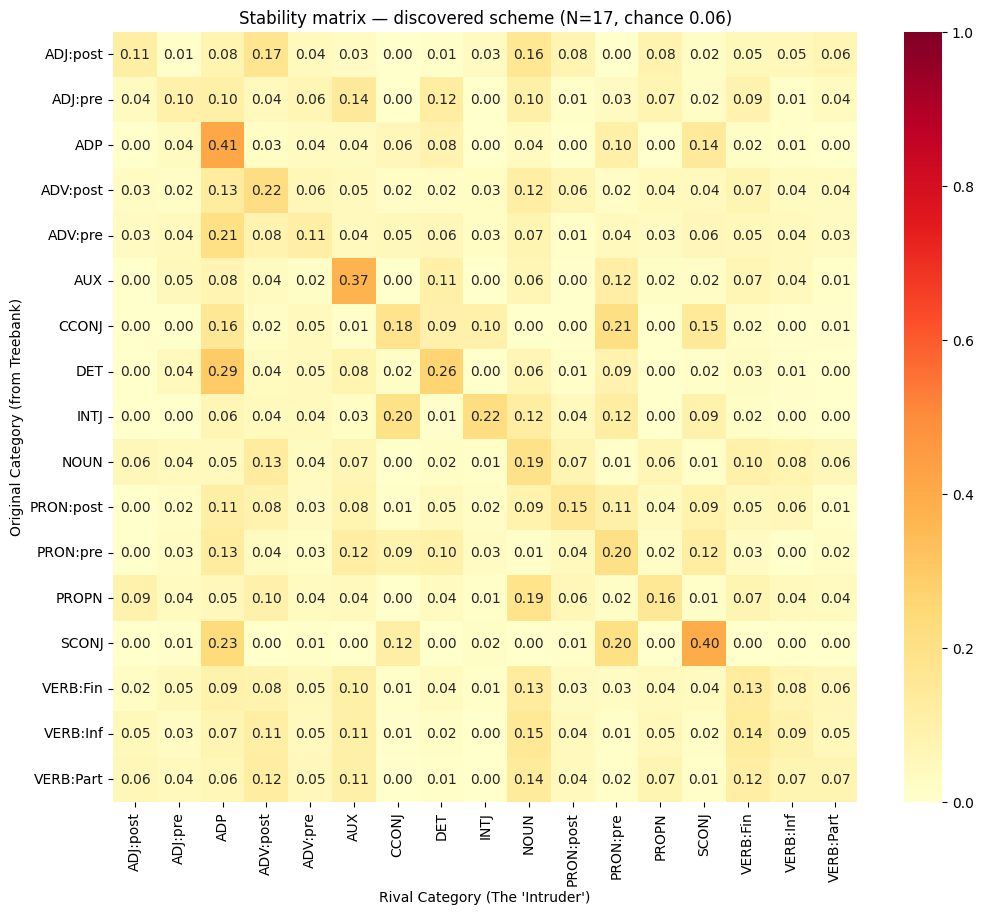

In [22]:
stability_matrix = build_transition_matrix(similarities_matrix,
                                           idx2lexunit, category_freqs)
print(f"mean self-stability: {np.diag(stability_matrix.values).mean():.3f} "
      f"(chance {1 / len(stability_matrix):.3f})")
plot_transition_matrix(
    stability_matrix,
    f"Stability matrix — discovered scheme "
    f"(N={len(stability_matrix)}, chance {1 / len(stability_matrix):.2f})",
    drop_categories=("X", "SYM"))


### Overlap analysis — bridge words, pulling features, radar charts

In [23]:
def get_pulling_features_by_mass(
    lex_unit, rival_category,
    feature_matrix, similarity_matrix,
    idx2lexunit, lexunit2idx,
    idx2feature, feature2idx,
    feature_mask=None,
    top_k_features=20,
    sim_threshold=0.7, max_neighbours=20,
):
    """Features that actually build the unit↔rival cosine similarity.
 
    Restrict to the active space, L2-normalise the unit (û) and each rival
    neighbour, average the normalised rivals into a direction r̂, then rank
    features by ûᵢ · r̂ᵢ. These contributions sum to the mean cosine similarity
    between the unit and its rival-category neighbours, so `share` tells you how
    much of the overlap each feature is responsible for.
    """
    unit_idx = lexunit2idx[lex_unit]
 
    cols = np.where(feature_mask)[0] if feature_mask is not None \
        else np.arange(feature_matrix.shape[1])
 
    u = feature_matrix[unit_idx, cols].astype(float)
    u_norm = np.linalg.norm(u)
    if u_norm == 0:
        return []
    u_hat = u / u_norm
 
    candidate_idx = np.where(similarity_matrix[unit_idx] >= sim_threshold)[0]
    neighbour_indices = sorted(
        [i for i in candidate_idx if i != unit_idx],
        key=lambda i: similarity_matrix[unit_idx][i], reverse=True,
    )[:max_neighbours]
    rival_neighbour_indices = [
        i for i in neighbour_indices if idx2lexunit[i][1] == rival_category
    ]
    if not rival_neighbour_indices:
        print(f"No neighbours of category '{rival_category}' found for {lex_unit}.")
        return []
 
    rival_block = feature_matrix[np.ix_(rival_neighbour_indices, cols)].astype(float)
    rn = np.linalg.norm(rival_block, axis=1, keepdims=True)
    rn[rn == 0] = 1.0
    rival_hat = (rival_block / rn).mean(axis=0)
 
    contribution = u_hat * rival_hat          # sums to mean cosine similarity
    total = contribution.sum()
 
    order = np.argsort(contribution)[::-1][:top_k_features]
    rows = []
    for local_i in order:
        c = contribution[local_i]
        if c <= 0:
            continue
        g_idx = int(cols[local_i])
        rows.append({
            "feature":      idx2feature[g_idx],
            "unit_value":   float(u[local_i]),
            "rival_dir":    float(rival_hat[local_i]),
            "contribution": float(c),
            "share":        float(c / total) if total > 0 else 0.0,
        })
    return rows

In [24]:
# NB units/categories follow the §4 scheme now:
LEX_UNIT  = ('devoir', 'VERB:Fin')
RIVAL_CAT = "AUX:Fin"
 
results = get_pulling_features_by_mass(
    LEX_UNIT, RIVAL_CAT,
    feature_matrix, similarities_matrix,
    idx2lexunit, lexunit2idx,
    idx2feature, feature2idx,
    top_k_features=20,
)
 
print(f"Top features building the {LEX_UNIT} → {RIVAL_CAT} similarity ")
print(f"{'Feature':<48} {'unit':>6}  {'r_dir':>6}  {'contrib':>8}  {'share':>6}")
print("-" * 82)
for r in results:
    print(f"{r['feature']:<48} {r['unit_value']:>6.3f}  {r['rival_dir']:>6.3f}  "
          f"{r['contribution']:>8.4f}  {r['share']:>5.1%}")

No neighbours of category 'AUX:Fin' found for ('devoir', 'VERB:Fin').
Top features building the ('devoir', 'VERB:Fin') → AUX:Fin similarity 
Feature                                            unit   r_dir   contrib   share
----------------------------------------------------------------------------------


In [25]:
def get_top_bridge_words(scores_dict, original_cat, rival_cat, top_n=100):
    """Words from `original_cat` most pulled toward `rival_cat`."""
    matches = [
        {"word": word, "purity": float(d["purity"]), "entropy": float(d["entropy"])}
        for (word, o_cat), d in scores_dict.items()
        if o_cat == original_cat and d["rival_category"] == rival_cat
    ]
    # Lowest combined score first — least pure, highest entropy.
    # matches.sort(key=lambda x: 0.7 * x["purity"] - 0.3 * x["entropy"])
    matches.sort(key=lambda x: x["purity"])
    return [(m["word"], f'{m["purity"]:.2f}', f'{m["entropy"]:.2f}')
            for m in matches[:top_n]]

def get_aggregate_pulling_features_by_mass(
    scores_dict, original_cat, rival_cat,
    feature_matrix, similarity_matrix,
    idx2lexunit, lexunit2idx,
    idx2feature, feature2idx,
    feature_mask=None,
    top_k_words=10, top_k_features=20,
    sim_threshold=0.7, max_neighbours=20,
):
    bridge_words = get_top_bridge_words(scores_dict, original_cat, rival_cat,
                                        top_n=top_k_words)
    if not bridge_words:
        print(f"No bridge words found from {original_cat} to {rival_cat}")
        return None
 
    print(f"Analyzing {len(bridge_words)} bridge words: "
          f"{[w[0] for w in bridge_words]}\\n")
 
    per_feature = {}
    for word, _p, _e in bridge_words:
        lex_unit = (word, original_cat)
        if lex_unit not in lexunit2idx:
            continue
        feats = get_pulling_features_by_mass(
            lex_unit=lex_unit, rival_category=rival_cat,
            feature_matrix=feature_matrix, similarity_matrix=similarity_matrix,
            idx2lexunit=idx2lexunit, lexunit2idx=lexunit2idx,
            idx2feature=idx2feature, feature2idx=feature2idx,
            feature_mask=feature_mask,
            top_k_features=top_k_features * 3,
            sim_threshold=sim_threshold, max_neighbours=max_neighbours,
        )
        for fd in feats:
            d = per_feature.setdefault(
                fd["feature"],
                {"contribs": [], "unit_values": []},
            )
            d["contribs"].append(fd["contribution"])
            d["unit_values"].append(fd["unit_value"])
 
    if not per_feature:
        print("No features collected — check bridge words and similarity threshold.")
        return None
 
    rows = [{
        "feature":        fname,
        "count_words":    len(d["contribs"]),
        "total_contrib":  float(np.sum(d["contribs"])),
        "avg_contrib":    float(np.mean(d["contribs"])),
        "avg_unit_value": float(np.mean(d["unit_values"])),
    } for fname, d in per_feature.items()]
    rows.sort(key=lambda r: r["total_contrib"], reverse=True)
    return pd.DataFrame(rows[:top_k_features])

In [26]:
ORIGINAL_CAT = "AUX:Part"
RIVAL_CAT    = "NOUN"
 
df_mass = get_aggregate_pulling_features_by_mass(
    scores_dict=scores,
    original_cat=ORIGINAL_CAT, rival_cat=RIVAL_CAT,
    feature_matrix=feature_matrix,
    similarity_matrix=similarities_matrix,
    idx2lexunit=idx2lexunit, lexunit2idx=lexunit2idx,
    idx2feature=idx2feature, feature2idx=feature2idx,
    top_k_words=40, top_k_features=25,
)
 
if df_mass is not None:
    print(df_mass.to_string(index=False))

No bridge words found from AUX:Part to NOUN


In [27]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SLOT_RE = re.compile(r"^node:X:([^:]+):")
def bridge_table(scores, original_cat, rival_cat):
    """All candidates, with the quantities that actually define a bridge."""
    rows = []
    for (word, cat), d in scores.items():
        if cat != original_cat or d["rival_category"] != rival_cat:
            continue
        p, r = float(d["purity"]), float(d["rival_weight_ratio"])
        rows.append({"word": word, "purity": p, "rival_share": r,
                     "entropy": float(d["entropy"]),
                     "concentration": p + r,     # mass in just these two categories
                     "bridge_score": r - p})     # >0 = more rival-like than own-like
    cols = ["word", "purity", "rival_share", "entropy",
            "concentration", "bridge_score"]
    return (pd.DataFrame(rows, columns=cols)   # columns survive empty sets
              .sort_values("bridge_score", ascending=False))

In [28]:
def select_bridge_words(scores, original_cat, rival_cat,
                        min_bridge_score=0.0, min_concentration=0.7, max_n=None):
    t = bridge_table(scores, original_cat, rival_cat)
    t = t[(t["bridge_score"] >= min_bridge_score) &
          (t["concentration"] >= min_concentration)]
    if max_n:
        t = t.head(max_n)
    return t["word"].tolist()

In [29]:
if not (bridge_words := set(select_bridge_words(scores, ORIGINAL_CAT, RIVAL_CAT))):
    raise ValueError(f"no bridge words {ORIGINAL_CAT} -> {RIVAL_CAT} under the "
                     "current thresholds - pick another overlap or relax "
                     "select_bridge_words")
#to get the number of occurrences so we know how representative the results are
occ_all = {w:n_occ[lexunit2idx[(w, ORIGINAL_CAT)]] for (w,c) in idx2lexunit.values() if c == ORIGINAL_CAT}
nb_occ_bridge = np.array([v for w,v in occ_all.items() if w in bridge_words])
nb_occ_non_bridge = np.array([v for w,v in occ_all.items() if w not in bridge_words])
print(f"bridge {ORIGINAL_CAT}: median {np.median(nb_occ_bridge):.0f} occ, "
          f"{np.mean(nb_occ_bridge <= 3):.0%} occur 3x or fewer (n={len(nb_occ_bridge)})")
print(f"other  {ORIGINAL_CAT}: median {np.median(nb_occ_non_bridge):.0f} occ, "
          f"{np.mean(nb_occ_non_bridge <= 3):.0%} occur 3x or fewer (n={len(nb_occ_non_bridge)})")


ValueError: no bridge words AUX:Part -> NOUN under the current thresholds - pick another overlap or relax select_bridge_words

In [30]:
bridge_ids = np.array([lexunit2idx[(w, ORIGINAL_CAT)] for w in bridge_words], dtype=int)
orig_ids = np.array([i for i, lu in idx2lexunit.items() if lu[1] == ORIGINAL_CAT and i not in bridge_ids], dtype=int)
rival_ids = np.array([i for i, lu in idx2lexunit.items() if lu[1] == RIVAL_CAT], dtype=int)

p_orig, p_bridge, p_rival = feature_matrix[orig_ids].mean(axis=0), feature_matrix[bridge_ids].mean(axis=0), feature_matrix[rival_ids].mean(axis=0)

rows = []
for j, f in idx2feature.items():
    if "=" not in f:
        continue
    var, value = f.rsplit("=", 1)
    slot = SLOT_RE.match(f).group(1)
    rows.append({"variable": var.replace("node:X:", ""), "value": value,
                    "slot": slot, "tier": "syllable" if "Syl" in slot else "token",
                    "p_orig": p_orig[j], "p_bridge": p_bridge[j], "p_rival": p_rival[j]})

df = pd.DataFrame(rows)
df["gap_rival_orig"] = df["p_rival"] - df["p_orig"]
df["position"] = np.where(np.abs(df["gap_rival_orig"]) > 1e-9, (df["p_bridge"] - df["p_orig"]) / df["gap_rival_orig"], np.nan) 
df.attrs["cats"] = (ORIGINAL_CAT, RIVAL_CAT)
df.attrs["n"] = dict(zip(["orig", "bridge", "rival"], [len(orig_ids), len(bridge_ids), len(rival_ids)]))
df.attrs["bridge_words"] = bridge_words

/var/folders/mg/9cp9yr5152g510k_59bb0gsh0000gn/T/ipykernel_35025/3512929447.py:5: RuntimeWarning: Mean of empty slice.
  p_orig, p_bridge, p_rival = feature_matrix[orig_ids].mean(axis=0), feature_matrix[bridge_ids].mean(axis=0), feature_matrix[rival_ids].mean(axis=0)
/opt/homebrew/lib/python3.11/site-packages/numpy/core/_methods.py:121: RuntimeWarning: divide by zero encountered in divide
  ret = um.true_divide(
/opt/homebrew/lib/python3.11/site-packages/numpy/core/_methods.py:121: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


In [31]:
def pick_axes(df, tier=None, n_axes=8, min_gap=0.08):
    """One axis per variable: the value that best separates the two categories"""
    d = df if tier is None else df[df["tier"] == tier]
    d = d[abs(d["gap_rival_orig"]) > min_gap]
    best = (d.sort_values("gap_rival_orig", ascending=False)
              .drop_duplicates("variable")
              .head(n_axes).copy())
    best["label"] = best["variable"] + " = " + best["value"]
    return best.sort_values("gap_rival_orig", ascending=False).reset_index(drop=True)

def axes_from_labels(df, labels):
    """Build the axis frame from an explicit list of 'variable = value' strings,
    in the order given. Bypasses the automatic gap-based selection."""
    d = df.copy()
    d["label"] = d["variable"] + " = " + d["value"]
    missing = [l for l in labels if l not in set(d["label"])]
    if missing:
        raise ValueError(f"not found in df: {missing}")
    return (d[d["label"].isin(labels)]
              .set_index("label").loc[labels].reset_index())


In [32]:
def plot_radars(df, n_axes=8, min_gap=0.08, manual=None):
    o, r = df.attrs["cats"]
    series = [(f"typical {o}", "p_orig", "tab:blue"),
              (f"bridge {o}", "p_bridge", "tab:red"),
              (f"typical {r}", "p_rival", "tab:orange")]
    
    if manual:
        tiers = list(manual)
    else:
        tiers = [t for t in ["token", "syllable"]
                 if len(pick_axes(df, t, n_axes, min_gap)) >= 3]
                 
    fig, axs = plt.subplots(1, len(tiers), figsize=(7.5 * len(tiers), 7),
                            subplot_kw=dict(polar=True), dpi=300)
    axs = np.atleast_1d(axs)
    
    for ax, tier in zip(axs, tiers):
        a = axes_from_labels(df, manual[tier]) if manual \
            else pick_axes(df, tier, n_axes, min_gap)
        
        ang = np.linspace(0, 2 * np.pi, len(a), endpoint=False).tolist()
        ang += ang[:1]
        
        for name, col, c in series:
            v = a[col].tolist()
            v += v[:1]
            ax.plot(ang, v, color=c, linewidth=2, label=name)
            ax.fill(ang, v, color=c, alpha=0.07)
            
        top = float(np.ceil(a[["p_orig", "p_bridge", "p_rival"]].values.max() * 10) / 10)
        ax.set_ylim(0, top)
        
        ticks = np.linspace(0, top, 3)[1:]
        ax.set_yticks(ticks)
        
        # INCREASED FONT SIZE for the inner circle numbers (from 7 to 10)
        ax.set_yticklabels([f"{t:.0%}" for t in ticks], fontsize=10)
        
        formatted_labels = [label.replace(" = ", "\n= ") for label in a["label"]]
        
        ax.set_xticks(ang[:-1])
        ax.set_xticklabels(formatted_labels, fontsize=12, ha="center")
        
        ax.tick_params(axis='x', pad=15)
        ax.spines['polar'].set_visible(False)
        
        # INCREASED PAD to push the subtitle away from the plot (from 26 to 40)
        ax.set_title(f"{tier} tier", pad=40, fontsize=14)
        
    axs[0].legend(loc="upper left", bbox_to_anchor=(-0.5, 1.1), frameon=False, fontsize=14)
    
    fig.suptitle(f"{o} bridge words towards {r}", fontsize=16, fontweight="bold")
    
    # ADJUSTED RECT to bring the main title slightly down and frame everything nicely
    fig.tight_layout(rect=[0, 0, 1, 1])
    
    plt.show()

plot_radars(df, n_axes=8, min_gap=0.08, manual=None)

ValueError: Number of columns must be a positive integer, not 0

<Figure size 0x2100 with 0 Axes>

if plotting manual to get results from paper:

<!-- # DET->ADP
# plot_radars(df, manual={
#     "token": [
#         "own:Foot = Begin",        # proclisis: bridge 0.40 ≈ ADP 0.43, typical DET 0.26
#         "own:Group = Begin",       # proclisis: bridge 0.47 ≈ ADP 0.46, typical DET 0.31
#         "next:Group = Unique",     # binding: 0.09 bridge / 0.24 DET / 0.07 ADP
#         "next:Group = In",         # domain size: 0.20 / 0.19 / 0.38 — no convergence with ADP
#         "next:Group = Last",       # domain size: bridge 0.62 overshoots both
#         "prev:Group = Last",       # preceding context partly converges: 0.33 vs ADP 0.40
#     ],
#     "syllable": [
#         "childSyl1:Duration = Dur_short",      # 0.31 / ADP 0.37 / DET 0.20
#         "childSyl1:PitchRangeGlo = L",         # 0.82 = ADP
#         "childSyl1:SlopeGlo = Flat",           # 0.71, near ADP 0.69
#         "prevSyl:Duration = Dur_long",         # largest syllable-tier gap
#         "nextSyl:Duration = Dur_short",        # following syllable short for ADP, not DET
#         "nextSyl:SemitonesFromUtteranceMean = F0_low",  # following syllable low
#     ],
# }) -->

<!-- #ADJ->NOUN
# plot_radars(df, manual={
#     "token": [
#         "own:Group = Last",        # finality: 0.46 bridge / 0.33 ADJ / 0.63 NOUN
#         "own:Package = Unique",
#         "own:Foot = Last",         # finality: 0.39 / 0.23 / 0.45
#         "prev:Group = Begin",      # preceding word opens the constituent: 0.29 / 0.17 / 0.37
#         "prev:Foot = Begin",       # same, foot level: 0.30 / 0.14 / 0.28
#         "own:Group = Unique",      # loss of autonomy: bridge lower than typical ADJ
        
#         "prev:LiaisonAfter = Yes", # non-convergence: 0.02 bridge / 0.02 ADJ / 0.17 NOUN
#     ],
#     "syllable": [
#         "prevSyl:Duration = Dur_short",                  # 0.29 / 0.22 / 0.39, preceding syllable
#         "prevSyl:SemitonesFromUtteranceMean = F0_low",   # 0.37 / 0.29 / 0.39, run-up to accent
#         "nextSyl:AvgHeightGlo = M",                      # following syllable, mild
#         "nextSyl:PitchRangeGlo = L",                     # following syllable, mild
#     ],
# }) -->

<!-- #adv->adp
# plot_radars(df, manual={
#     "token": [
#         "own:Group = Begin",       # non-convergence: bridge 0.20 stays near ADV 0.13, far from ADP 0.46
#         "own:Foot = Begin",        # non-convergence: bridge 0.21 vs ADP 0.43
#         "next:Group = Begin",      # boundary after: bridge 0.55, higher than ADV 0.34 and ADP 0.23
#         "next:Group = Unique",     # boundary after: word following stands alone more than for ADP
#         "next:RhythmGroup = Strong",  # convergence: following word rhythmically strong, near ADP
#         "own:Package = Begin",     # detachment: bridge opens own package, partial move
#     ],
#     "syllable": [
#         "prevSyl:Duration = Dur_long",      # detachment: lengthening before, 0.47 vs ADV 0.34
#         "nextSyl:PitchRangeGlo = L",        # melodic convergence
#         "prevSyl:SemitonesFromUtteranceMean = F0_low",  # check this exists; if not, drop to 5
#         "nextSyl:SlopeGlo = Flat",          # melodic convergence on following syllable
        
#         "nextSyl:AvgHeightGlo = M",         # melodic convergence
#         "childSyl1:AvgHeightGlo = M",       # own first syllable, mild
        
#     ],
# }) -->

<!-- #verb->aux
plot_radars(df, manual={
    "token": [
        "own:RhythmGroup = Weak",  # overshoot: 0.77 bridge / 0.34 VERB / 0.54 AUX
        "own:FootType = Weak",     # overshoot: 0.79 / 0.36 / 0.64
        "prev:FootType = Weak",    # overshoot: 0.82 / 0.42 / 0.63
        "own:Package = In",        # overshoot: 0.83 / 0.37 / 0.78
        "next:Group = Last",       # NON-convergence: 0.15 bridge stays near VERB 0.10, far from AUX 0.39
        "next:Foot = Last",        # NON-convergence: 0.17 / 0.11 / 0.34
    ],
    "syllable": [
        "prevSyl:Duration = Dur_short",     # reduction, preceding syllable: 0.47 / 0.29 / 0.47
        "childSyl1:Duration = Dur_short",   # reduction, own first syllable: 0.47 / 0.28 / 0.41 (overshoots)
        "nextSyl:SlopeGlo = Rise",          # following syllable — bridge does NOT converge (0.06/0.08/0.20)
        "nextSyl:Duration = Dur_mid",       # following syllable, mild
    ],
}) -->

*(NB: the manual axis labels above were chosen for the paper's 12-category run; with the discovered scheme, re-derive them from `pick_axes` before reusing.)*

In [ ]:
d = df[df["variable"].isin(["next:Group","next:Foot","next:Package"])]
print(d[["variable","value","p_orig","p_bridge","p_rival","gap_rival_orig"]].round(2).to_string(index=False))
print(f"variables passing min_gap: {len(pick_axes(df, None, n_axes=10**6))}")

print(df.attrs["n"])
print("\nvariables that separate the categories most:\n")
print(pick_axes(df, None, 30)[
    ["label", "tier", "p_orig", "p_bridge", "p_rival", "gap_rival_orig", "position"]
].round(2).to_string(index=False))

In [ ]:
def displacement_test(bridge_ids, original_cat, rival_cat,
                      space="prosody_pure", n_perm=1000, seed=0):
    rng = np.random.default_rng(seed)


    excl = set(bridge_ids.tolist())
    pool = np.array([i for i, lu in idx2lexunit.items()
                     if lu[1] == original_cat and i not in excl])
    rival_ids = np.array([i for i, lu in idx2lexunit.items() if lu[1] == rival_cat])

    p_orig, p_rival = feature_matrix[pool].mean(0), feature_matrix[rival_ids].mean(0)
    axis = p_rival - p_orig
    denom = axis @ axis

    proj = lambda v: float((v - p_orig) @ axis / denom)   # 0 = at orig, 1 = at rival

    bocc = np.array([n_occ[i] for i in bridge_ids])
    pocc = np.array([n_occ[i] for i in pool])
    obs = proj(feature_matrix[bridge_ids].mean(0))

    null = np.empty(n_perm)
    for k in range(n_perm):
        pick = []
        for o in bocc:
            cand = pool[pocc == o]
            if len(cand) == 0:
                cand = pool[np.abs(pocc - o) <= 1]
            pick.append(rng.choice(cand if len(cand) else pool))
        null[k] = proj(feature_matrix[pick].mean(0))

    p = (null >= obs).mean()
    print(f"{original_cat}->{rival_cat}: observed displacement {obs:.3f}, "
          f"null {null.mean():.3f} (sd {null.std():.3f}), "
          f"z = {(obs - null.mean())/null.std():.2f}, p = {p:.4f}")
    return obs, null


# displacement_test(bridge_ids, ORIGINAL_CAT, RIVAL_CAT)
displacement_test(bridge_ids, ORIGINAL_CAT, RIVAL_CAT)